# Thermal Expansion of Single-Crystal Copper from 300 to 800 K: Prediction and Numerical Assessment of the Mishin EAM1 Potential

**Authors:** [Full names of all group members]<br>
**Affiliation:** [University and School of Materials Science and Engineering]

## Abstract

Thermal expansion provides a finite-temperature test of an interatomic potential beyond its description of a relaxed crystal. Here, classical molecular dynamics simulations were performed in LAMMPS to assess the Mishin EAM1 potential for periodic face-centered cubic copper between 300 and 800 K. A 4,000-atom crystal was simulated at six temperatures under isotropic NPT conditions with a target pressure of 0 bar. Three independently initialized trajectories were sampled at each temperature, and additional endpoint calculations examined system size, integration timestep, and simulation duration. The lattice parameter increased from 3.63193 to 3.66441 Å, corresponding to a linear expansion of 0.8944% and a volume increase of 2.7074%. The engineering interval-average linear expansion coefficient was **17.888 × 10⁻⁶ K⁻¹**, with a 95% statistical confidence-interval half-width of 0.015 × 10⁻⁶ K⁻¹ across three repeats. After conversion to the same 300 K reference, the corresponding NIST SRM 736 value was 18.6038 × 10⁻⁶ K⁻¹, giving a relative deviation of **−3.85%**. Each tested numerical change altered the coefficient by less than 0.1%, substantially less than this reference discrepancy. These results support a stable prediction of positive thermal expansion within the tested protocol, while distinguishing numerical robustness from experimental accuracy. The available observables do not identify a unique physical origin for the remaining discrepancy.

**Keywords:** single-crystal copper; molecular dynamics; embedded-atom method; thermal expansion; numerical sensitivity

## 1. Introduction

Thermal expansion connects atomic interactions with dimensional changes that matter in materials processing and service. When neighboring components expand by different amounts, their mechanical constraints can generate thermal stresses. Copper is therefore a useful model material for examining how an atomistic description reproduces a measurable thermal response. Alper and Politzer investigated its temperature-dependent behavior using molecular dynamics in a context relevant to metallic components in microelectronic systems [1]. For a periodic crystal, the lattice parameter and simulation-cell volume are directly accessible quantities, allowing a relatively simple model to support a quantitative assessment rather than only a qualitative visualization.

The central modeling issue is the temperature dependence of the equilibrium volume. A relaxed lattice at zero temperature characterizes a minimum of the potential-energy surface; thermal expansion instead depends on the response sampled away from that minimum. In an ideal harmonic description with a fixed reference structure, symmetric vibrations alone do not produce the required shift of the equilibrium spacing. An anharmonic description is therefore essential. In classical molecular dynamics, this response is sampled through atomic trajectories on the chosen potential-energy surface. The resulting expansion reflects both that interaction model and the statistical protocol used to estimate its finite-temperature averages.

Several computational approaches address this problem, but their assumptions differ. Narasimhan and de Gironcoli combined density functional calculations, density functional perturbation theory, and the quasiharmonic approximation to investigate the thermal properties of copper and the influence of exchange-correlation approximations [2]. In that framework, volume-dependent vibrational frequencies contribute to the equilibrium thermodynamics. Molecular dynamics instead samples the finite-temperature response of a specified potential directly, subject to classical statistical mechanics and finite simulation time. A comparison between these approaches must consequently distinguish the interaction model from the treatment of temperature; a more elaborate model is not automatically more accurate for every observable.

Thermal expansion has also been used to validate modern potentials. Lysogorskiy et al. included copper thermal expansion in their assessment of the atomic cluster expansion implementation PACE [3]. Olsson et al. investigated the influence of microstructure on copper expansion using classical molecular dynamics and electronic-structure calculations [4]. Their work illustrates why the material state must be specified when comparing coefficients: a periodic single crystal and a nanocrystalline material contain different atomic environments. These studies motivate expansion as a useful validation quantity, while also showing that results from unlike structures or coefficient definitions cannot be placed on a common accuracy scale without further analysis.

The Mishin EAM1 potential offers a practical starting point for a course-scale investigation. Its original development and evaluation addressed structural stability and lattice defects in copper [5], and the NIST repository provides an identifiable parameter file [7]. These properties make the model reproducible and scientifically motivated. However, successful predictions of static structures or defects do not establish the accuracy of an interval-average thermal expansion coefficient. That quantity requires its own finite-temperature calculation and an experimental comparison with a consistent reference length.

The present study asks **how accurately the Mishin EAM1 potential predicts the 300–800 K interval-average expansion of ideal periodic copper, and whether the observed deviation is comparable to the numerical effects examined here**. Six temperature points and three independent initializations provide the main dataset. Endpoint calculations then test size, timestep, and duration, while the experimental comparison explicitly reconciles reference temperatures. The contribution is a reproducible and critically assessed benchmark of an established model. Reproducing the known positive expansion of copper is not presented as a new physical discovery.

## 2. Computational Methods

### 2.1. Crystal model and interatomic potential

The simulation cell contained 10 × 10 × 10 conventional FCC unit cells, giving 4,000 Cu atoms. Its axes were aligned with [100], [010], and [001], and periodic boundary conditions were applied in all three directions. The initial lattice parameter was 3.615 Å. Atomic coordinates and cell dimensions were relaxed by conjugate-gradient minimization before the finite-temperature calculations. The static structural check identified FCC environments for all 4,000 atoms and a relaxed lattice parameter of approximately 3.61500 Å. This establishes the intended starting structure; it does not by itself demonstrate that all subsequent finite-temperature configurations remain free of defects.

The periodic cell represents a bulk-like single crystal without initial grain boundaries or free surfaces. Replicating a conventional cell produces a finite atomistic model whose translational periodicity removes an external surface but restricts the wavelengths that can be represented. Thus, periodic boundaries reduce surface-related complications without eliminating finite-size effects. The larger endpoint model used below tests one increase in size, rather than establishing a complete thermodynamic-limit extrapolation.

Atomic interactions were described using the Mishin copper EAM1 potential [5], and trajectories were integrated with LAMMPS [6]. The embedded-atom energy has the form

$$E=\sum_i F(\rho_i)+\frac{1}{2}\sum_{i\ne j}\phi(r_{ij}),\qquad
\rho_i=\sum_{j\ne i}f(r_{ij}).\tag{1}$$

Here, $F$ is the embedding contribution, $\rho_i$ is the local density contribution from neighboring atoms, and $\phi$ is the pair contribution. This environment-dependent form allows a metallic many-body description at a computational cost suitable for repeated sampling. The specific file was **`Cu01.eam.alloy`**, identified as EAM1 in the NIST repository and read using the LAMMPS `eam/alloy` pair style [7]. No potential parameters were refitted. The analysis therefore evaluates one existing parameterization, rather than an EAM model class or a newly optimized potential.

### 2.2. Finite-temperature simulation protocol

Independent initial velocities were generated at 300, 400, 500, 600, 700, and 800 K, using three different random seeds at each temperature. The temperatures were simulated separately rather than sampled along a single continuous heating trajectory. This choice reduces dependence on an inherited heating history and permits an estimate of variability across independent initializations. It does not replace equilibration at each state point, because every initialized crystal must still adjust to its finite-temperature equilibrium volume.

The main simulations used an isotropic NPT ensemble with a scalar target pressure of 0 bar. The Nosé–Hoover-type temperature and pressure controls implemented in LAMMPS were used with a timestep of 1 fs, a temperature damping time of 0.1 ps, and a pressure damping time of 1 ps [8]. A second time integrator was not applied to the same atoms. Isotropic cell changes preserve a cubic simulation box and are consistent with the scalar expansion investigated here. This setup does not independently measure direction-dependent thermal strains or the response to a deviatoric load.

Allowing the volume to fluctuate is central to the measurement. At fixed volume, heating could produce an internal pressure response without permitting the crystal to adopt a new mean length. Under NPT conditions, the box can adjust and its equilibrated mean dimensions become the observable of interest. The target pressure is an imposed control parameter; instantaneous pressure fluctuations and a small nonzero finite-trajectory mean are expected to be assessed statistically rather than treated as evidence that the input pressure was different from zero.

Each main trajectory contained 200 ps of equilibration followed by 500 ps of production sampling. Scalar quantities were recorded every 0.1 ps, yielding 5,000 production samples per trajectory. The equilibration segment was excluded from reported means. This separation fixes the statistical definition of the analysis before comparison with the reference and prevents initial cell adjustment from being averaged into the production estimate. The numerical settings and their endpoint variants are summarized in Table 1.

**Table 1. Main simulation protocol and endpoint sensitivity calculations.** Parameters not explicitly varied were retained at their main-protocol values. Validation trajectories were analyzed separately from the three production repeats.

| Parameter | Main protocol | Endpoint variation |
|:---|:---|:---|
| Structure and atom count | FCC; 4,000 atoms; three-dimensional periodicity | 12³ conventional cells; 6,912 atoms |
| Temperatures and repeats | 300–800 K in 100 K increments; three repeats per temperature | 300 and 800 K; one trajectory per condition and endpoint |
| Target pressure and cell control | 0 bar; isotropic | Unchanged |
| Integration timestep | 1 fs | 0.5 fs for the timestep check |
| Temperature / pressure damping | 0.1 ps / 1 ps | Unchanged |
| Equilibration + production | 200 ps + 500 ps | 1,000 ps + 1,000 ps for the duration check |
| Scalar recording interval | 0.1 ps | Unchanged |
| Number of trajectories | 18 production trajectories | Six validation trajectories |

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
from IPython.display import display, Image, HTML
from run_study import manifest, folder
from analyze_study import read_job, reference
from md_project import plotting
jobs = manifest()
checked = [read_job(job)[0] for job in jobs]
assert len(checked) == 24
for job in jobs:
    meta = json.loads((folder(job)/"metadata.json").read_text(encoding="utf8"))
    text = (folder(job)/"input.in").read_text(encoding="ascii")
    assert hashlib.sha256(text.encode("ascii")).hexdigest() == meta["input_sha256"]
figdir = Path("results/paper_figures"); figdir.mkdir(exist_ok=True)
display(HTML("<style>" + Path("docs/paper_style.css").read_text(encoding="utf8") + "</style>"))
plt = plotting()
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
# Show the actual model and integration settings without rerunning MD.
for file in ["outputs/model/build.in", "outputs/production/prod_T300_r1/input.in"]:
    text = Path(file).read_text(encoding="ascii")
    keys = ("lattice ", "region ", "boundary ", "pair_style ", "pair_coeff ", "timestep ", "fix integrator ", "run ")
    print("\n" + file)
    print("\n".join(line for line in text.splitlines() if line.startswith(keys)))


outputs/model/build.in
boundary p p p
lattice fcc 3.615
region box block 0 10 0 10 0 10 units lattice
pair_style eam/alloy
pair_coeff * * potentials/Cu01.eam.alloy Cu
run 0

outputs/production/prod_T300_r1/input.in
boundary p p p
pair_style eam/alloy
pair_coeff * * potentials/Cu01.eam.alloy Cu
timestep 0.001
fix integrator all npt temp 300 300 0.1 iso 0 0 1
run 200000
run 500000


### 2.3. Observables and coefficient definition

For each recorded configuration, the lattice parameter was calculated as $a=L_x/n$, where $n$ is the number of conventional cells along the box edge. The three edges change together under isotropic cell control. Lattice parameters and volumes were averaged over the production segment of each trajectory before the independent repeats were summarized. Volume was read directly from the trajectory output rather than reconstructed by cubing an averaged lattice parameter. These observables describe the changing dimensions of the periodic crystal, not a directly imaged interatomic bond length.

The normalized linear expansion and engineering interval-average coefficient were defined using 300 K as the reference:

$$\epsilon(T)=\frac{\bar a(T)-\bar a(300)}{\bar a(300)},\qquad
\bar\alpha_{300-800}=\frac{\epsilon(800)}{800-300}.\tag{2}$$

The normalization was applied separately to each repeat using its own 300 K value. The three endpoint coefficients were subsequently averaged. This sequence keeps the reference length and high-temperature length paired within a repeat and supplies three independent coefficient estimates for the final uncertainty calculation. The same grouping was retained when constructing the normalized curves and residuals.

**The coefficient in Eq. (2) is an endpoint secant quantity**, expressed per kelvin. It is distinct from the instantaneous coefficient $\alpha(T)=a(T)^{-1}\mathrm{d}a/\mathrm{d}T$. In particular, a nearly straight lattice-parameter curve over a finite interval does not establish a temperature-independent instantaneous coefficient. The intermediate temperatures constrain the observed trend, while the principal reported coefficient uses only the 300 and 800 K endpoints. Higher-order fitting and numerical differentiation were avoided because six temperature points do not justify a detailed reconstruction of the instantaneous temperature dependence.

### 2.4. Experimental reference and statistical analysis

The experimental benchmark was the revised NIST SRM 736 certificate dated 7 October 1990 [9]; Hahn reports the underlying copper thermal-expansion measurements [10]. The certificate tabulates length changes relative to 293 K. A direct comparison with Eq. (2) would therefore mix reference lengths. The tabulated fractional changes $e_{293}(T)$ were converted according to

$$\epsilon_{\mathrm{ref}}(T)=\frac{1+e_{293}(T)}{1+e_{293}(300)}-1.\tag{3}$$

Using the revised values of 117 ppm at 300 K and 9,420 ppm at 800 K gives an interval-average reference coefficient of 18.6038 × 10⁻⁶ K⁻¹. The factor $10^{-6}$ was applied when converting the tabulated ppm values into fractional length changes. The revision, temperature interval, and reference length were kept consistent throughout. A room-temperature instantaneous coefficient would answer a different question and was not substituted for this interval benchmark.

Successive molecular-dynamics samples are correlated. Accordingly, the 5,000 recorded production points were not treated as 5,000 independent experiments. Following established approaches to correlated-data uncertainty and sampling assessment [11,12], the trajectories were divided into blocks of 1, 2, 5, 10, 20, and 50 ps. Twenty-picosecond blocks were used for single-trajectory standard-error diagnostics, and the first and second halves of each production segment were compared. Changes with block length were inspected because recording more frequently does not necessarily add proportionate independent information.

For the final coefficient, the uncertainty was calculated from the three independently initialized coefficient estimates. The mean was reported with a two-sided 95% Student-$t$ confidence interval using two degrees of freedom. This interval assumes independent repeats and an adequate approximation for the distribution of their estimates. **It quantifies sampling variability, not total predictive uncertainty.** Neither experimental-reference uncertainty nor systematic model error was included. The small number of repeats also limits how precisely the sampling distribution itself can be characterized.

The endpoint checks increased the atom count to 6,912, reduced the timestep to 0.5 fs, or extended both equilibration and production to 1 ns. Each modified endpoint pair was compared with production repeat r1, using the previously specified practical target of an absolute coefficient change below 2%. This target screens numerical sensitivity under the chosen changes; it is not a universal convergence criterion or a significance test. The calculations did not sample all combinations of these parameters or repeat the same scan at intermediate temperatures.

In [3]:
runs = pd.DataFrame(checked)
prod = runs[runs.group == "production"]
a = prod.pivot(index="temperature", columns="replicate", values="a_A")
v = prod.pivot(index="temperature", columns="replicate", values="volume_A3")
eps = a.div(a.loc[300], axis=1) - 1
alpha = eps.loc[800] / 500
tcrit = 4.3026527299
estimate = alpha.mean()
halfwidth = tcrit * alpha.std(ddof=1) / np.sqrt(3)
ref, refalpha = reference()
bias = 100 * (estimate / refalpha - 1)
checks = pd.read_csv("results/validation_comparison.csv")
assert np.isclose(estimate * 1e6, 17.8882558243, rtol=1e-8)
print(f"Interval-average coefficient = {estimate*1e6:.3f} ± {halfwidth*1e6:.3f} ×10⁻⁶ K⁻¹ (95% statistical confidence interval)")
print(f"NIST = {refalpha*1e6:.4f} ×10⁻⁶ K⁻¹; relative deviation = {bias:.2f}%")

Interval-average coefficient = 17.888 ± 0.015 ×10⁻⁶ K⁻¹ (95% statistical confidence interval)
NIST = 18.6038 ×10⁻⁶ K⁻¹; relative deviation = -3.85%


## 3. Results and Discussion

### 3.1. Temperature dependence of lattice parameter and volume

The mean lattice parameter increased at every sampled temperature, demonstrating positive thermal expansion within the investigated interval (Figure 1). It rose from 3.63193 Å at 300 K to 3.66441 Å at 800 K, a difference of approximately 0.03248 Å. The associated normalized linear expansion was 0.8944%. This change was much larger than the statistical variability across the three repeats, so the temperature-driven increase was resolved by the present sampling. Lines connecting points indicate the sequence of simulated temperatures and do not introduce an additional fitted model.

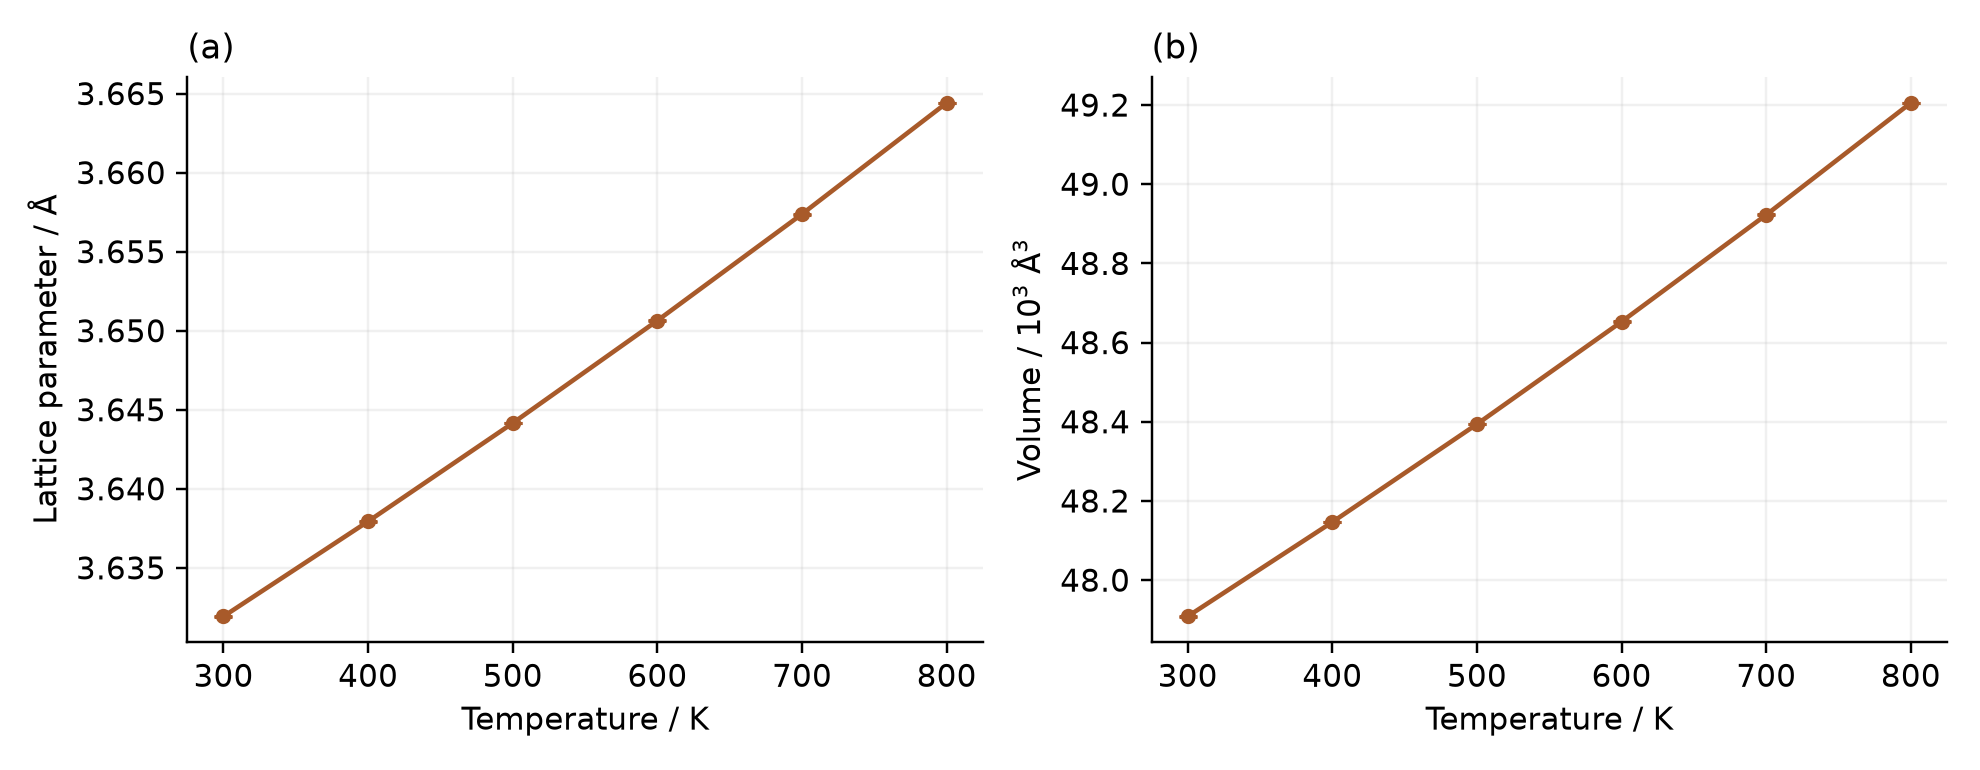

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
for panel, data, scale, ylabel in [(ax[0], a, 1, "Lattice parameter / Å"), (ax[1], v, 1e-3, r"Volume / $10^3$ Å$^3$")]:
    panel.errorbar(data.index, data.mean(axis=1)*scale, yerr=tcrit*data.std(axis=1)/np.sqrt(3)*scale,
                   fmt="o-", color="#a85a2a", capsize=3, ms=4)
    panel.set(xlabel="Temperature / K", ylabel=ylabel)
    panel.grid(alpha=.18)
for panel, tag in zip(ax, ["(a)", "(b)"]): panel.set_title(tag, loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(figdir/"figure1_lattice_volume.png", dpi=220)
display(Image(filename=str(figdir/"figure1_lattice_volume.png"))); plt.close(fig)

**Figure 1. Temperature dependence of the periodic copper crystal.** (a) Mean lattice parameter and (b) mean simulation-cell volume. Each point summarizes three independently initialized trajectories; error bars denote 95% Student-$t$ confidence intervals with two degrees of freedom and may be smaller than the symbols. Volume was averaged directly from the recorded cell volumes. Connecting lines are guides to the eye.

The corresponding mean volume increased from approximately 47,908.4 to 49,205.5 Å³, or 2.7074%. For a uniformly expanding cubic box, the exact relation between deterministic linear and volumetric strains is $(1+\epsilon)^3-1=3\epsilon+3\epsilon^2+\epsilon^3$. The leading small-strain term therefore explains why the observed volumetric expansion is close to three times the linear expansion. The higher-order terms remain finite, and averaging a fluctuating volume is not identical to cubing an averaged edge length. The agreement is consequently a useful geometric consistency check, without providing an independent validation against experiment.

The result establishes the direction and magnitude of expansion predicted by this potential under the imposed conditions. It does not isolate a microscopic mechanism from the scalar curve alone. The potential includes a nonquadratic energy landscape, so an anharmonic finite-temperature response is consistent with the calculation. However, no mode-resolved vibrational analysis or decomposition of the expansion into separate microscopic contributions was performed. The supported observation is the equilibrium dimensional response of this model, rather than a direct measurement of a particular phonon mechanism.

### 3.2. Comparison with a consistently normalized experimental benchmark

After conversion to a common 300 K reference, both the simulation and the NIST data showed increasing length with temperature, but the simulated expansion became progressively smaller than the reference (Figure 2). The two curves coincide at 300 K by definition. That coincidence contains no independent evidence that the absolute simulated lattice parameter is experimentally accurate at this temperature. The residual panel therefore carries essential information: it displays the difference between normalized responses rather than relying on the visual proximity of two increasing curves.

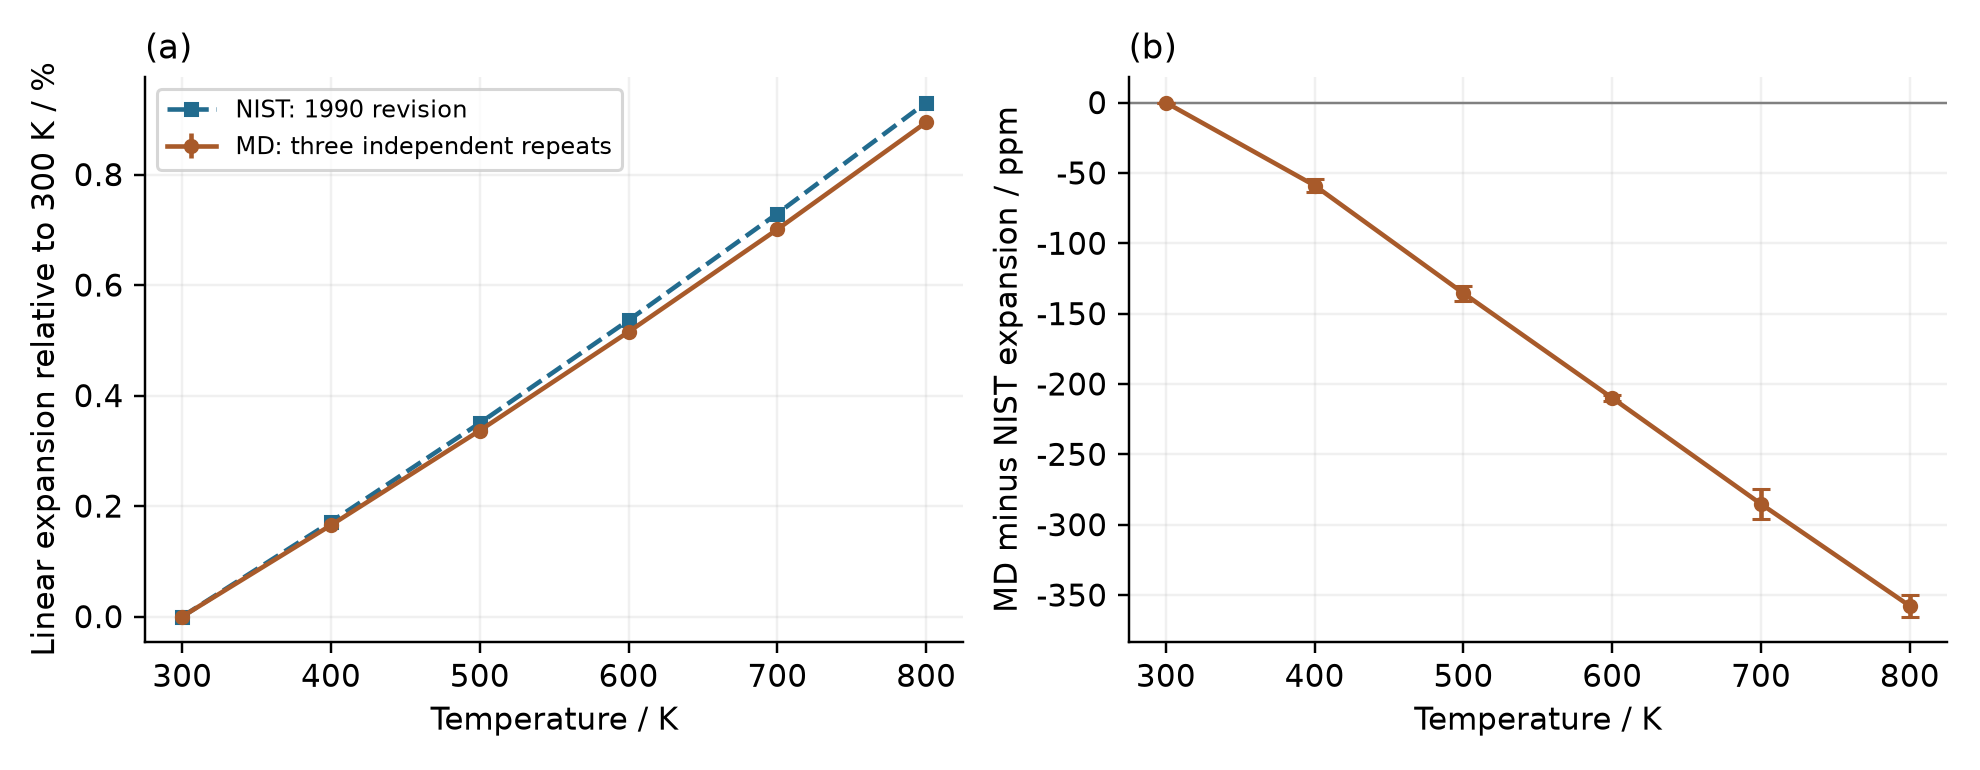

In [5]:
mean_eps = eps.mean(axis=1)
ci_eps = tcrit * eps.std(axis=1) / np.sqrt(3)
reference_eps = ref.set_index("temperature_K").strain_from_300.reindex(eps.index)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
ax[0].errorbar(eps.index, mean_eps*100, yerr=ci_eps*100, fmt="o-", color="#a85a2a", ms=4, label="MD: three independent repeats")
ax[0].plot(eps.index, reference_eps*100, "s--", color="#226b8e", ms=4, label="NIST: 1990 revision")
ax[0].set(xlabel="Temperature / K", ylabel="Linear expansion relative to 300 K / %")
ax[0].legend(fontsize=8)
ax[1].axhline(0, color="gray", lw=.8)
ax[1].errorbar(eps.index, (mean_eps-reference_eps)*1e6, yerr=ci_eps*1e6,
               fmt="o-", color="#a85a2a", capsize=3, ms=4)
ax[1].set(xlabel="Temperature / K", ylabel="MD minus NIST expansion / ppm")
for panel, tag in zip(ax, ["(a)", "(b)"]):
    panel.set_title(tag, loc="left", fontsize=11); panel.grid(alpha=.18)
fig.tight_layout()
fig.savefig(figdir/"figure2_reference_residual.png", dpi=220)
display(Image(filename=str(figdir/"figure2_reference_residual.png"))); plt.close(fig)

**Figure 2. Normalized expansion relative to the revised NIST benchmark.** (a) Linear expansion relative to 300 K and (b) the MD-minus-NIST residual in ppm. MD uncertainty bars were calculated from the three separately normalized repeats, retaining their shared 300 K reference within each repeat. Experimental measurement and tabulation uncertainties were not propagated into these bars. Reference values were taken from page 1 of the revised certificate [9].

At 800 K, the normalized length-change residual was approximately −358 ppm. Dividing this endpoint residual by the 500 K interval gives a coefficient difference of approximately −0.716 × 10⁻⁶ K⁻¹. This conversion links the curve-level comparison with the coefficient-level comparison in Table 2. It also distinguishes a relative error in the expansion coefficient from a relative error in the absolute lattice parameter: the −3.85% value below describes the former, not a 3.85% error in the crystal edge length.

**Table 2. Engineering interval-average linear expansion coefficients from 300 to 800 K.** Coefficients and interval half-widths are expressed in 10⁻⁶ K⁻¹. The MD estimate is the mean of three independently calculated coefficients. Relative deviation uses the NIST coefficient as the denominator. No combined reference uncertainty was propagated; its omission does not imply zero uncertainty.

In [6]:
table = pd.DataFrame({"Source": ["MD: three independent repeats", "NIST SRM 736 revised table"],
    "Interval-average coefficient": [f"{estimate*1e6:.3f}", f"{refalpha*1e6:.4f}"],
    "95% CI half-width": [f"{halfwidth*1e6:.3f}", "Not propagated"],
    "Deviation from NIST": [f"{bias:.2f}%", "Reference"]})
display(table.style.hide(axis="index"))

Source,Interval-average coefficient,95% CI half-width,Deviation from NIST
MD: three independent repeats,17.888,0.015,-3.85%
NIST SRM 736 revised table,18.6038,Not propagated,Reference


The individual MD coefficients were approximately 17.885, 17.895, and 17.885 × 10⁻⁶ K⁻¹. Their mean, **17.888 × 10⁻⁶ K⁻¹**, was lower than the consistently defined reference by **3.85%**. The 95% statistical interval half-width of 0.015 × 10⁻⁶ K⁻¹ was much smaller than the coefficient discrepancy. Variation caused by the independently generated initial velocities is therefore insufficient to explain the difference in this dataset. Increasing the number of repeats might refine the uncertainty estimate, but a narrower statistical interval would not by itself move the mean toward the reference.

The comparison also involves different material representations. The certificate characterizes actual high-purity copper specimens, whereas the calculation starts from a perfect periodic crystal. The present normalization compares changes relative to a common temperature and deliberately removes a constant reference-length offset. This is appropriate for evaluating expansion, but it leaves the accuracy of the absolute lattice parameter unresolved. A separate absolute-length benchmark and a fuller account of the experimental specimen would be needed to assess those additional questions.

### 3.3. Equilibration diagnostics and numerical sensitivity

The production averages provided no obvious indication of a persistent mismatch with the imposed temperature targets. Across all 24 trajectories, the largest absolute difference between the mean and target temperature was 0.249 K, and mean pressures ranged from −7.57 to 5.85 bar. Endpoint traces of temperature, pressure, potential energy, and volume fluctuated without sustained one-direction growth over the displayed sampling windows (Figure S1). These diagnostics are consistent with the intended stationary sampling, although matching a mean target alone cannot establish equilibration of every structural degree of freedom.

The first-half versus second-half lattice-parameter diagnostic reached a maximum standardized difference of 2.246 when normalized by the corresponding block-based uncertainty estimate. This did not trigger the workflow's strong-drift review condition. Nevertheless, a finite trajectory can contain slow processes that are not resolved by a two-window comparison. The diagnostic was therefore used together with time-series inspection and the longer endpoint calculations, rather than as a binary proof of complete equilibrium.

The numerical variations produced small changes in the endpoint coefficient relative to r1 (Figure 3). Increasing the atom count from 4,000 to 6,912 changed it by +0.0680%; halving the timestep changed it by −0.0087%; and extending both equilibration and sampling changed it by +0.0280%. All were below the prespecified 2% practical target and below 0.1% in magnitude. The timestep result, in particular, did not reveal a substantial integration-step sensitivity at the precision relevant to the experimental comparison.

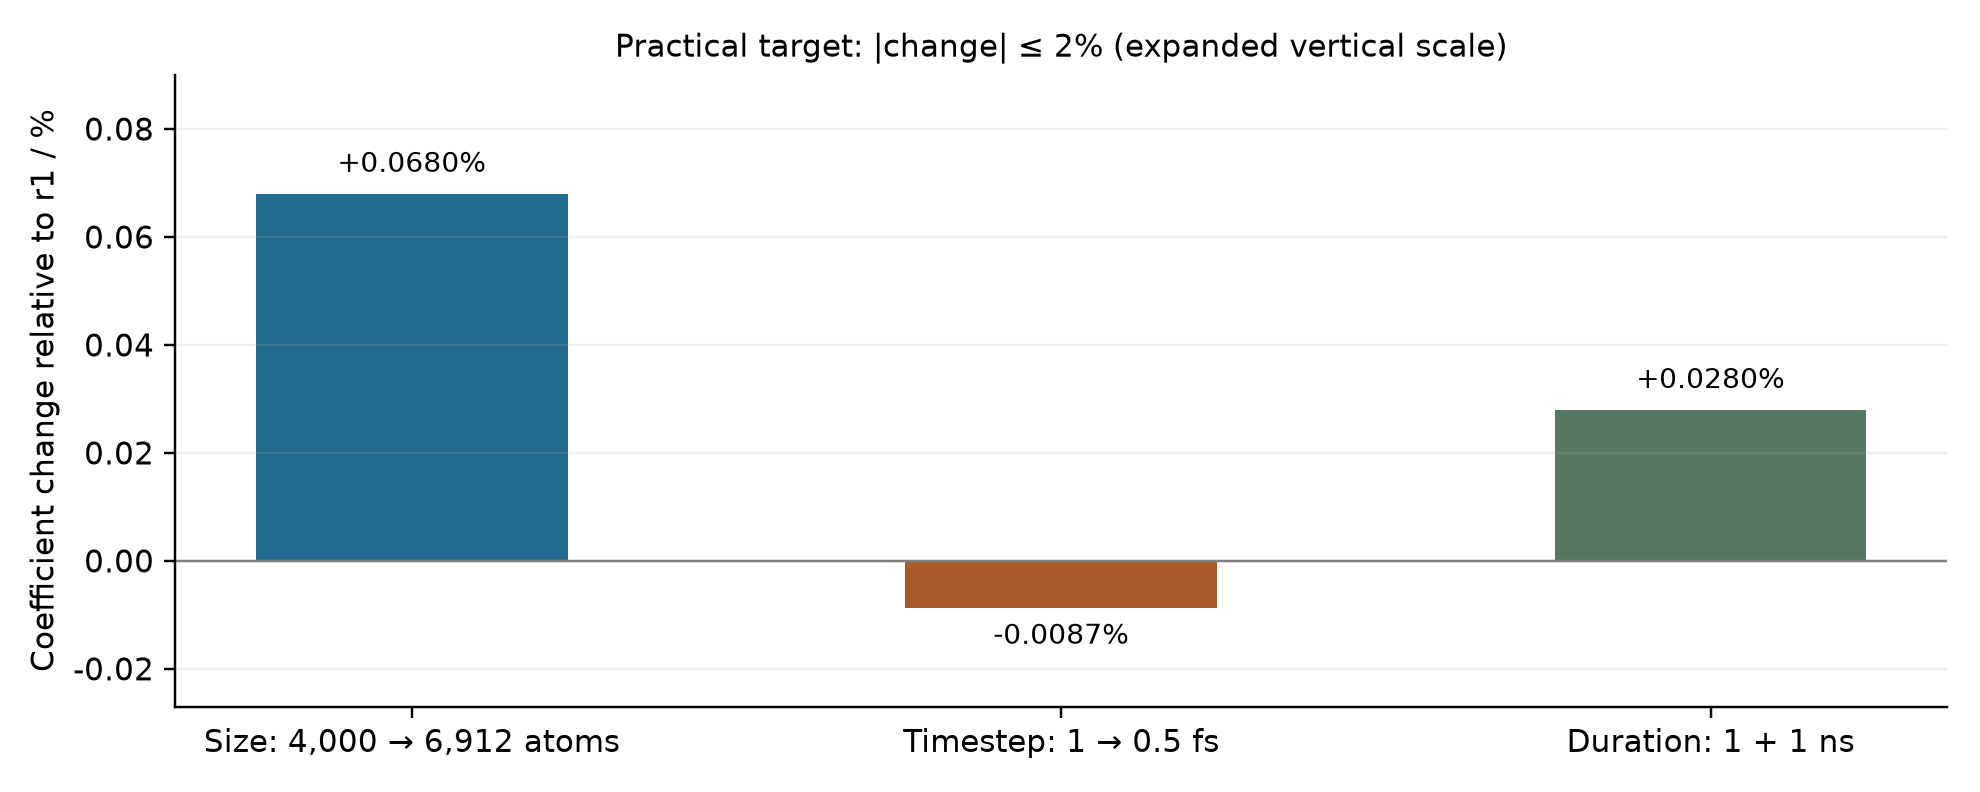

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.6))
bars = ax.bar(["Size: 4,000 → 6,912 atoms", "Timestep: 1 → 0.5 fs", "Duration: 1 + 1 ns"], checks.change_percent,
              color=["#226b8e", "#a85a2a", "#557764"], width=.48)
ax.axhline(0, color="gray", lw=.8)
ax.bar_label(bars, labels=[f"{x:+.4f}%" for x in checks.change_percent], padding=5, fontsize=9)
ax.set(ylabel="Coefficient change relative to r1 / %", ylim=(-.027, .09))
ax.set_title("Practical target: |change| ≤ 2% (expanded vertical scale)", fontsize=10)
ax.grid(axis="y", alpha=.18)
fig.tight_layout(); fig.savefig(figdir/"figure3_sensitivity.png", dpi=220)
display(Image(filename=str(figdir/"figure3_sensitivity.png"))); plt.close(fig)

**Figure 3. Sensitivity of the interval-average coefficient to endpoint protocol changes.** Each condition uses one trajectory at 300 K and one at 800 K and is compared with the r1 endpoint coefficient. These values were not referenced to the three-repeat pooled estimate. No confidence bars are shown because the modified conditions lack independent repeats. The vertical axis is expanded to resolve the small changes; the prespecified ±2% target lies outside its range. Labels report the actual percentage changes.

The three checks probe different possible numerical limitations. A larger box tests one change in the available periodic length scales; a smaller timestep tests integration resolution; and a longer trajectory tests the selected equilibration and averaging durations. Their small observed effects support the robustness of the current estimate within these specific comparisons. Because each modified condition has only one endpoint pair, the measured shifts also contain sampling variability. They should not be interpreted as exact corrections that can be added to the final coefficient, nor as rigorous upper bounds on all finite-size and integration errors.

Block-length analysis gives a complementary view of sampling uncertainty. Across the 24 trajectories, increasing the block duration from 20 to 50 ps gave a median standard-error ratio of 1.018, with individual ratios between 0.564 and 1.299. There was no systematic continued increase over this change; the endpoint r1 examples are shown in Figure S2. However, longer blocks leave fewer block averages, so the standard-error estimate itself becomes noisier. This behavior supports the use of correlation-aware diagnostics while leaving uncertainty about correlations slower than the available sampling window.

### 3.4. Interpretation in relation to previous computational work

**The reference discrepancy exceeds the numerical effects measured here.** The −3.85% coefficient deviation is substantially larger than the changes observed in the size, timestep, and duration checks. It is therefore not justified to attribute the discrepancy entirely to any of these tested choices, or to expect their specific tested adjustments to eliminate it. Conversely, three limited checks cannot exclude all numerical contributions. The defensible interpretation separates the measured small protocol sensitivity from the unresolved sources of the remaining difference.

The original Mishin study established the potential's performance for structural stability and defects [5]. That evidence supports its use as a physically motivated copper model, but different observables test different aspects of the same energy landscape. A minimum-energy structure and a finite-temperature change in equilibrium volume need not have the same error. The present result therefore adds an observable-specific assessment rather than contradicting the original model evaluation. It also illustrates why reproducibility and predictive accuracy must be reported separately: a coefficient can be calculated consistently and still retain a systematic discrepancy relative to a chosen benchmark.

The literature provides useful methodological comparisons without supplying a controlled ranking for this dataset. The first-principles study of Narasimhan and de Gironcoli examines thermal properties through quasiharmonic calculations and different exchange-correlation approximations [2]. PACE uses copper expansion as one component of potential validation [3]. Olsson et al. extend the problem to microstructure-dependent expansion and use electronic-structure information to investigate its origin [4]. The present work is narrower: it fixes one potential and one initial crystal type, then checks a reproducible classical-MD protocol. Since these publications differ in model, material state, and reported quantities, their results cannot be used to assign an accuracy advantage here without matching definitions and conditions.

Several model limitations remain relevant to interpretation. Classical MD does not explicitly include nuclear quantum statistics or electronic thermal excitation, and the initial perfect periodic crystal is not identical to a real specimen. The simulation also lacks a systematic finite-temperature defect inventory, phonon calculation, and electronic-structure analysis. These omissions identify possible directions for further work, but their numerical contributions have not been calculated. Assigning the observed bias uniquely to one omitted effect, or to a particular anharmonic term in the potential, would exceed the available evidence.

The next most informative extension would be a controlled comparison under an otherwise unchanged protocol. A second copper potential could test model dependence; a separate absolute lattice-parameter reference could test the baseline structure; and repeated endpoint validation could separate small parameter shifts from statistical fluctuations. These are distinct questions. Merely adding more points to the existing temperature curve would improve its resolution but would not, on its own, identify why the current model underpredicts the reference expansion.

## 4. Conclusions

Periodic single-crystal copper described by the Mishin EAM1 potential exhibited positive thermal expansion between 300 and 800 K at a target pressure of 0 bar. The lattice parameter increased from 3.63193 to 3.66441 Å, corresponding to 0.8944% linear expansion and 2.7074% volumetric expansion. Three independently initialized endpoint pairs yielded an engineering interval-average coefficient of **17.888 ± 0.015 × 10⁻⁶ K⁻¹**, where the stated uncertainty is the half-width of a 95% statistical confidence interval.

After conversion of the revised NIST SRM 736 data to the same 300 K reference, the MD coefficient was **3.85% lower** than the reference value of 18.6038 × 10⁻⁶ K⁻¹. The tested changes in atom count, timestep, and duration each altered the coefficient by less than 0.1%. The experimental discrepancy is therefore larger than the numerical changes measured in this study, while its physical origin remains unresolved. These findings support the potential as a reproducible model of the expansion trend under the tested conditions, with the reported quantitative bias retained explicitly. Neither the narrow statistical interval nor the passed practical sensitivity target establishes an unbiased model or complete convergence over untested conditions.

## Data and Code Availability

Inputs, scalar trajectory data, metadata, and analysis scripts are available in the [project repository](https://github.com/Gytid8/copper-thermal-expansion). This Notebook reads and reanalyzes the completed dataset; executing it does not restart the long MD runs. Two interrupted timestep-validation trajectories were resumed from their equilibrated states and then sampled for a complete 500 ps production segment. Original records and the removal of an identical duplicated restart-boundary row are documented in the [recovery record](https://github.com/Gytid8/copper-thermal-expansion/blob/main/docs/recovery_record.md). The authors must supply their actual names, affiliation, and contributions before submission.

## References

[1] Alper, H. E.; Politzer, P. Molecular dynamics simulation of the temperature-dependent behavior of solid copper. *Journal of Molecular Structure: THEOCHEM* **487**, 117–125 (1999). [DOI: 10.1016/S0166-1280(99)00147-5](https://doi.org/10.1016/S0166-1280(99)00147-5).

[2] Narasimhan, S.; de Gironcoli, S. Ab initio calculation of the thermal properties of Cu: Performance of the LDA and GGA. *Physical Review B* **65**, 064302 (2002). [DOI: 10.1103/PhysRevB.65.064302](https://doi.org/10.1103/PhysRevB.65.064302); [author manuscript](https://arxiv.org/abs/cond-mat/0109020).

[3] Lysogorskiy, Y.; van der Oord, C.; Bochkarev, A.; et al. Performant implementation of the atomic cluster expansion (PACE) and application to copper and silicon. *npj Computational Materials* **7**, 97 (2021). [DOI: 10.1038/s41524-021-00559-9](https://doi.org/10.1038/s41524-021-00559-9); [author manuscript](https://arxiv.org/abs/2103.00814).

[4] Olsson, P. A. T.; Awala, I.; Holmberg-Kasa, J.; et al. Grain Size-Dependent Thermal Expansion of Nanocrystalline Metals. *Materials* **16**, 5032 (2023). [DOI: 10.3390/ma16145032](https://doi.org/10.3390/ma16145032); [institutional full text](https://lucris.lub.lu.se/ws/portalfiles/portal/159582754/Olsson_2023c.pdf).

[5] Mishin, Y.; Mehl, M. J.; Papaconstantopoulos, D. A.; Voter, A. F.; Kress, J. D. Structural stability and lattice defects in copper: Ab initio, tight-binding, and embedded-atom calculations. *Physical Review B* **63**, 224106 (2001). [DOI: 10.1103/PhysRevB.63.224106](https://doi.org/10.1103/PhysRevB.63.224106).

[6] Thompson, A. P.; Aktulga, H. M.; Berger, R.; et al. LAMMPS—a flexible simulation tool for particle-based materials modeling at the atomic, meso, and continuum scales. *Computer Physics Communications* **271**, 108171 (2022). [DOI: 10.1016/j.cpc.2021.108171](https://doi.org/10.1016/j.cpc.2021.108171); [official software citation](https://www.lammps.org/about/citing/).

[7] NIST Interatomic Potentials Repository. *2001–Mishin et al.–Cu-1*: EAM1 identification and LAMMPS potential-file conversion. [Official entry](https://www.ctcms.nist.gov/potentials/entry/2001--Mishin-Y-Mehl-M-J-Papaconstantopoulos-D-A-et-al--Cu-1/). Accessed 19 October 2026.

[8] LAMMPS Documentation. *fix nvt / npt / nph commands*. [Official documentation](https://docs.lammps.org/fix_nh.html). Accessed 19 October 2026. Simulations used the 22 July 2025 release, update 4; online documentation can change with later releases.

[9] NIST. *Standard Reference Material 736: Copper—Thermal Expansion*. Certificate revised 7 October 1990, table on p. 1. [Official archived certificate](https://tsapps.nist.gov/srmext/certificates/archives/736.pdf).

[10] Hahn, T. A. Thermal Expansion of Copper from 20 to 800 K—Standard Reference Material 736. *Journal of Applied Physics* **41**, 5096–5101 (1970). [DOI: 10.1063/1.1658614](https://doi.org/10.1063/1.1658614). Numerical reference values in this study use the revised certificate [9].

[11] Flyvbjerg, H.; Petersen, H. G. Error estimates on averages of correlated data. *The Journal of Chemical Physics* **91**, 461–466 (1989). [DOI: 10.1063/1.457480](https://doi.org/10.1063/1.457480).

[12] Grossfield, A.; Patrone, P. N.; Roe, D. R.; Schultz, A. J.; Siderius, D. W.; Zuckerman, D. M. Best Practices for Quantification of Uncertainty and Sampling Quality in Molecular Simulations [Article v1.0]. *Living Journal of Computational Molecular Science* **1**(1), 5067 (2019). [DOI: 10.33011/livecoms.1.1.5067](https://doi.org/10.33011/livecoms.1.1.5067); [journal full text](https://livecomsjournal.org/index.php/livecoms/article/download/v1i1e5067/913/2595).

## Supplementary Material

### S1. Endpoint time-series diagnostics

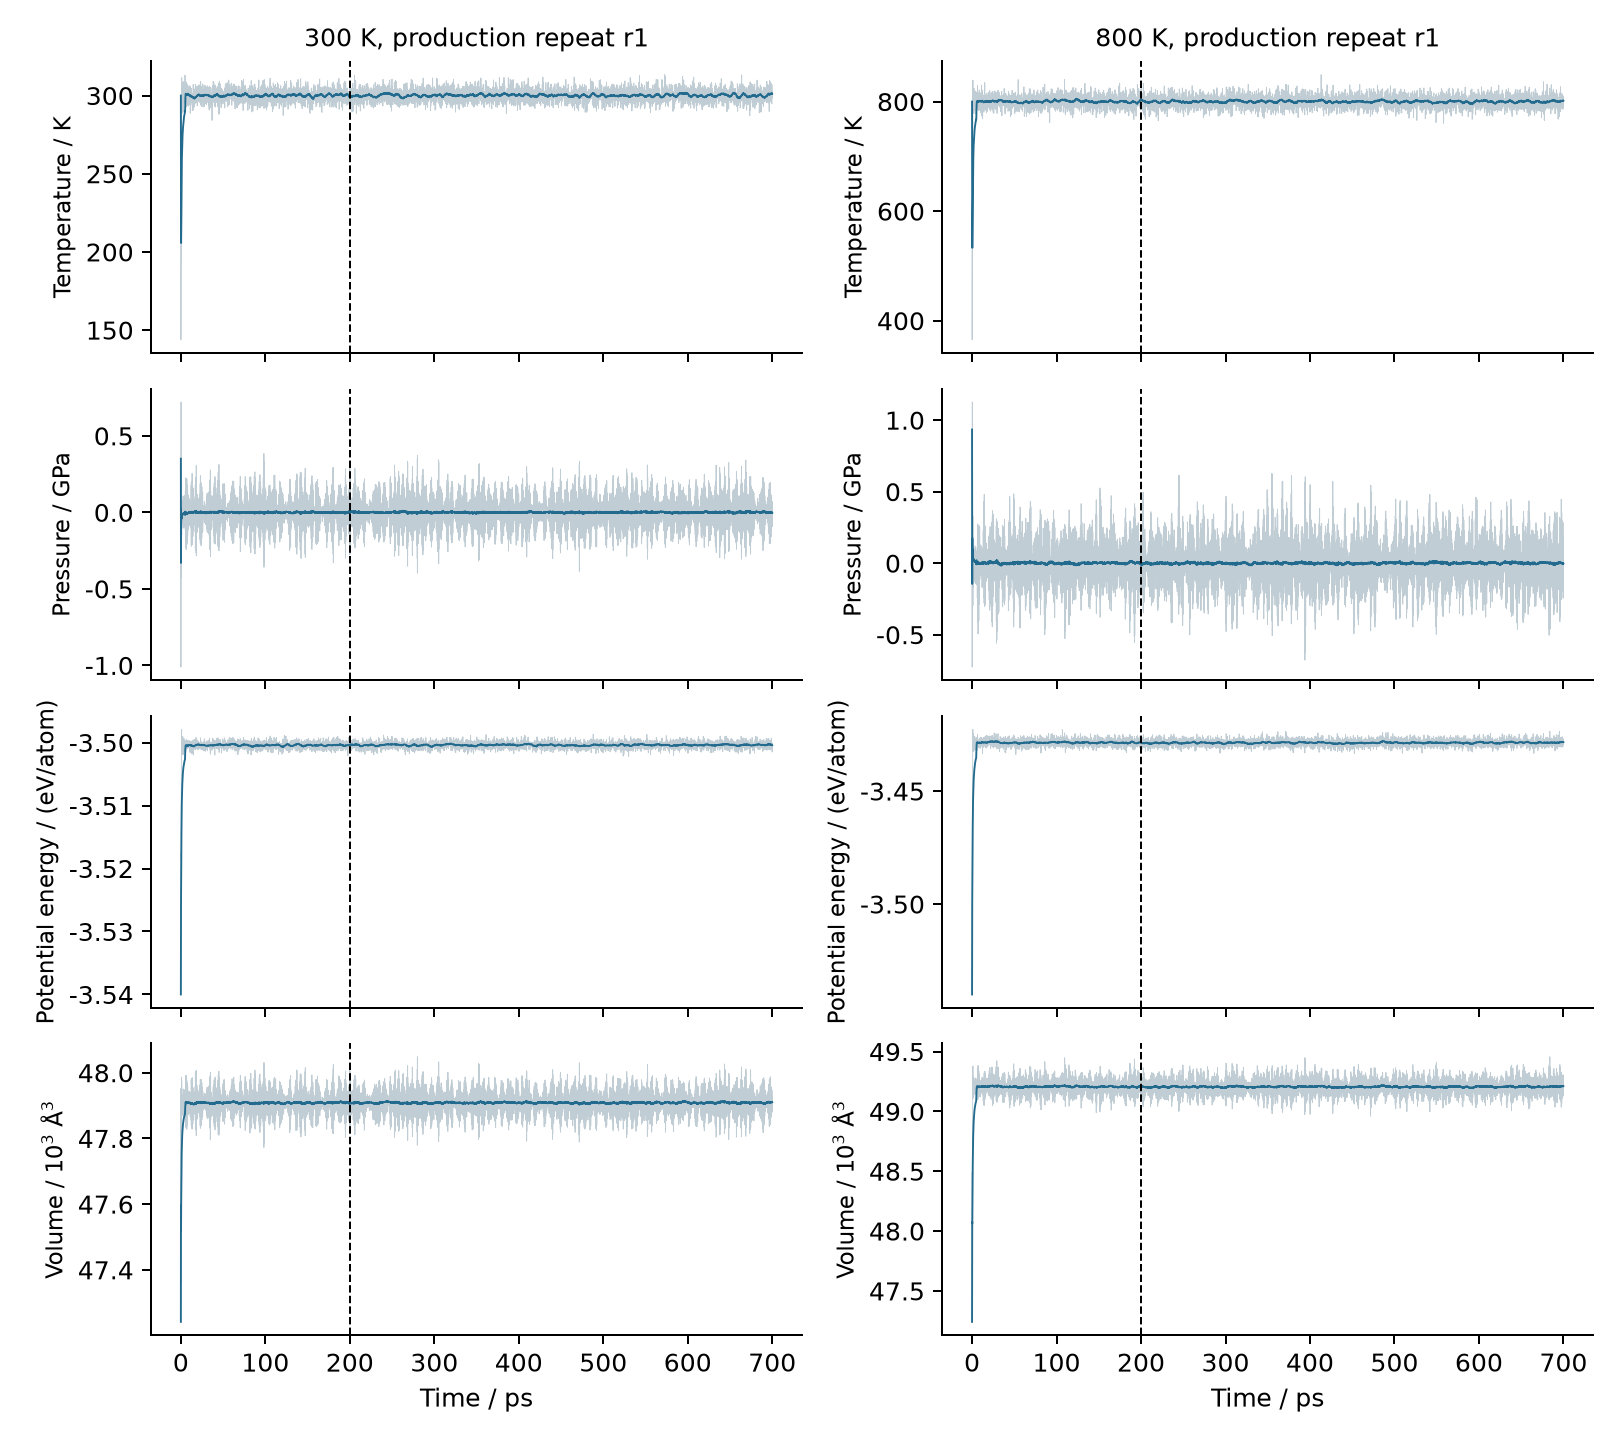

In [8]:
fig, axes = plt.subplots(4, 2, figsize=(9, 8), sharex=True)
keys = ["temperature_K", "pressure_bar", "potential_eV", "volume_A3"]
labels = ["Temperature / K", "Pressure / GPa", "Potential energy / (eV/atom)", r"Volume / $10^3$ Å$^3$"]
for col, temp in enumerate([300, 800]):
    job = next(j for j in jobs if j["id"] == f"prod_T{temp}_r1")
    frame = pd.read_csv(folder(job)/"thermo.dat", sep=r"\s+", comment="#", names=
        ["step", "time_ps", "temperature_K", "pressure_bar", "potential_eV", "lx_A", "ly_A", "lz_A", "volume_A3"])
    for row, (key, factor) in enumerate(zip(keys, [1, 1e-4, 1/4000, 1e-3])):
        panel = axes[row, col]; y = frame[key] * factor
        panel.plot(frame.time_ps, y, lw=.35, color="#c0cdd4")
        panel.plot(frame.time_ps, y.rolling(50, min_periods=1).mean(), lw=.75, color="#226b8e")
        panel.axvline(200, color="black", ls="--", lw=.8)
        panel.set_ylabel(labels[row], fontsize=9)
    axes[0, col].set_title(f"{temp} K, production repeat r1", fontsize=10)
    axes[-1, col].set_xlabel("Time / ps")
fig.tight_layout(); fig.savefig(figdir/"figureS1_endpoint_traces.png", dpi=180)
display(Image(filename=str(figdir/"figureS1_endpoint_traces.png"))); plt.close(fig)

**Figure S1. Endpoint production-repeat r1 trajectories at 300 and 800 K.** Rows show temperature, pressure, potential energy per atom, and cell volume. Light traces represent outputs at 0.1 ps intervals; dark traces are 5 ps rolling means for visualization only. The vertical dashed line marks the end of the 200 ps equilibration segment. Subsequent 500 ps data were used for the reported production averages. Pressure is expressed in GPa, with 1 bar = 10⁻⁴ GPa; large instantaneous fluctuations do not imply an incorrect target-pressure setting.

### S2. Sensitivity to statistical block length

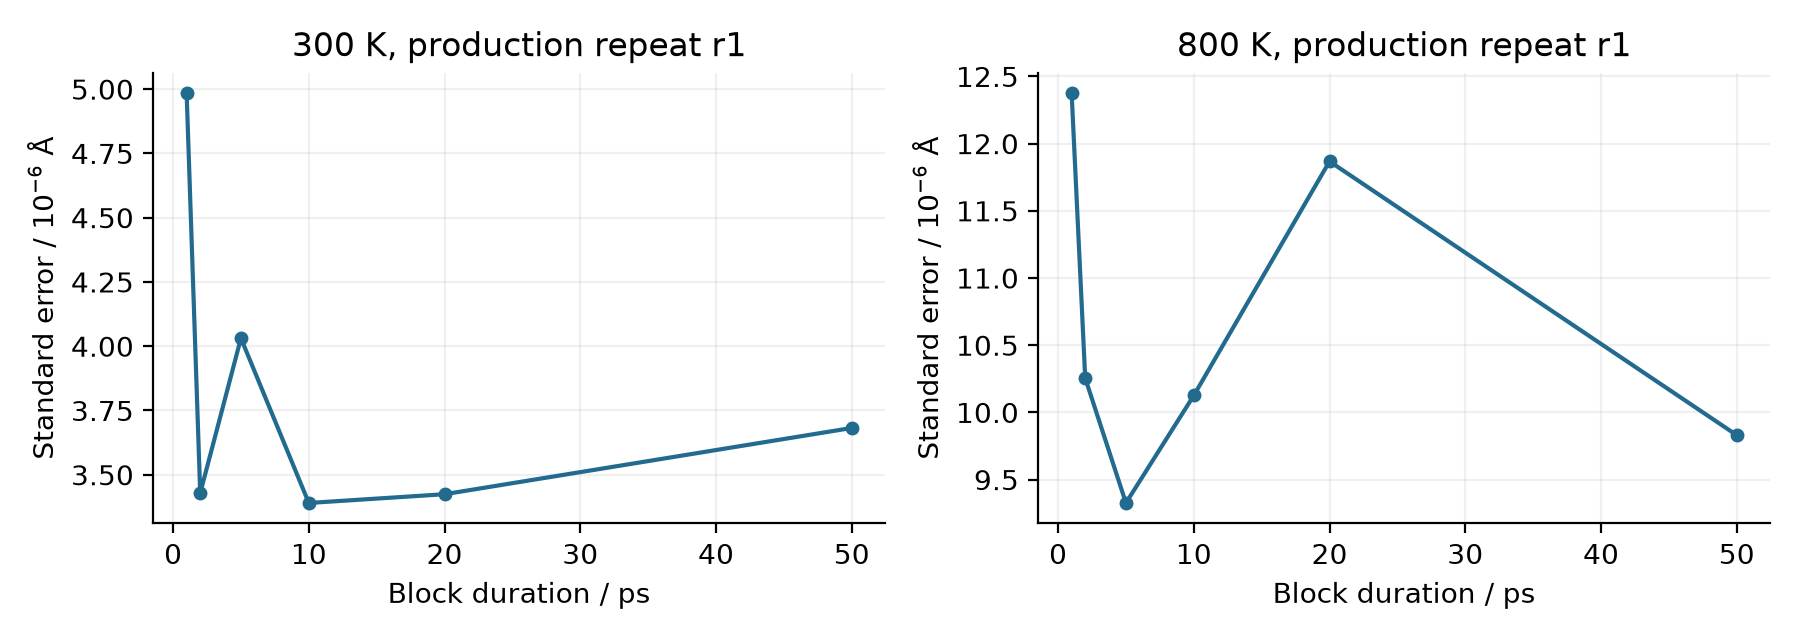

In [9]:
blocks = pd.read_csv("results/block_statistics.csv")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for panel, temp in zip(axes, [300, 800]):
    block = blocks[blocks.job == f"prod_T{temp}_r1"]
    panel.plot(block.block_ps, block.a_sem_A*1e6, "o-", ms=4, color="#226b8e")
    panel.set(xlabel="Block duration / ps", ylabel=r"Standard error / $10^{-6}$ Å", title=f"{temp} K, production repeat r1")
    panel.grid(alpha=.18)
fig.tight_layout(); fig.savefig(figdir/"figureS2_block_statistics.png", dpi=200)
display(Image(filename=str(figdir/"figureS2_block_statistics.png"))); plt.close(fig)

**Figure S2. Block-based standard errors for the endpoint r1 trajectories.** The standard error of the mean lattice parameter is estimated from block averages at each block duration. Longer blocks contain more correlated raw samples but reduce the number of available block averages. Local increases or decreases should therefore not be interpreted as strict convergence or divergence.

The complete 24-trajectory block analysis and half-window diagnostics are provided in `results/block_statistics.csv` and `results/run_summary.csv`. The citation audit is recorded in `docs/reference_verification.json`. Recovery and boundary-cleaning records preserve the provenance of the dataset and do not change the production-window definition.